# 🔬 BƯỚC 0: Đo Lường & Đánh Giá 3D Chuyên Sâu (Không Cần Huấn Luyện Lại)

**Tài liệu tham khảo**: `docs/FINE-TUNING-DOCS/MAMBA_UNET_REVIEW_AND_FIXES.md` (Mục 2: BƯỚC 0)

### 🎯 Mục Tiêu Đo Lường
Trước khi thực hiện chu kỳ fine-tuning mới, notebook này thực hiện đo lường khách quan mô hình hiện tại (ví dụ: checkpoint `mamba_colab_500item_25epoch_extra_test` với Val Dice 2D = 0.7456) qua 2 công cụ chẩn đoán chuyên sâu:

1. **Kiểm tra chất lượng Cache & FOV (`tools/check_cache.py`)**:
   - Đánh giá chỉ số `mask_in_lung_fraction`: Mặt nạ phổi tự động có vô tình cắt phạm vào khối u nằm sát màng phổi không?
   - Đánh giá nguy cơ mất nhãn khối u khi pad/crop nếu hạ `IMAGE_SIZE` từ 512 xuống 448 để tăng tốc độ huấn luyện.

2. **Quét ngưỡng xác suất & Đánh giá 3D mức bệnh nhân / nốt u (`tools/eval_sweep.py`)**:
   - Trả lời: **Ngưỡng nhị phân tối ưu thực sự là bao nhiêu?** (0.3, 0.4, 0.5, 0.6 hay 0.7?)
   - Định lượng: **Bao nhiêu dương tính giả trên mỗi ca bệnh (`fp_comps`)?**
   - Phân tích theo kích thước: **Độ nhạy phát hiện theo đường kính tương đương** (0-5mm, 5-10mm, 10-20mm, $\ge 20$mm).

3. **Trực quan hóa & Lưu trữ kết quả**:
   - Vẽ 4 biểu đồ then chốt: FROC curve, Precision-Recall, Dice 3D theo ngưỡng và độ nhạy theo kích thước nốt.
   - Toàn bộ CSV, biểu đồ PNG và báo cáo Markdown được tự động đồng bộ sang Google Drive.

---

In [1]:
# 1. Kiểm tra phần cứng và GPU khả dụng
!nvidia-smi

Wed Nov 11 09:46:28 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   41C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
# 2. Thiết lập môi trường PyTorch 2.6.0 (cu126) + Triton 3.3.1 & Thư viện y tế
import subprocess, sys

def probe(code):
    r = subprocess.run([sys.executable, "-c", code], capture_output=True, text=True)
    return r.stdout.strip() if r.returncode == 0 else None

TORCH_PROBE = "import torch;print(torch.__version__, int(torch._C._GLIBCXX_USE_CXX11_ABI))"
cur = probe(TORCH_PROBE)
print("Torch hiện tại:", cur)

if cur and cur.startswith("2.6.0+cu126") and cur.endswith(" 1"):
    print("⏭️ Đã có torch 2.6.0+cu126 (ABI=True), bỏ qua bước cài torch.")
else:
    print("🧹 Dọn dẹp và cài đặt PyTorch 2.6.0+cu126...")
    !rm -rf /usr/local/lib/python3.13/dist-packages/~* 2>/dev/null || true
    !pip uninstall torch torchvision torchaudio causal-conv1d mamba-ssm -y -q 2>/dev/null || true
    !pip install torch==2.6.0 torchvision==0.21.0 torchaudio==2.6.0 --index-url https://download.pytorch.org/whl/cu126 -q
    cur = probe(TORCH_PROBE)
    print("Torch sau khi cài:", cur)

assert cur and cur.startswith("2.6.0+cu126") and cur.endswith(" 1"), \
    f"❌ Torch chưa đúng (cần 2.6.0+cu126 và ABI=1, đang là: {cur}). Hãy thử chạy lại cell này."

print("\n⚙️ Cài đặt Triton 3.3.1 và các thư viện cần thiết...")
!python -m pip install triton==3.3.1 SimpleITK pandas scipy opencv-python-headless pyyaml matplotlib seaborn tabulate -q
trt = probe("import triton;print(triton.__version__, hasattr(triton,'set_allocator'))")
print("Triton:", trt)
assert trt and trt.endswith("True"), f"❌ Triton chưa có set_allocator (đang là: {trt})"

print("\n✅ CELL 2 XONG. Chạy tiếp cell 3 để mount Drive và nạp checkpoints.")

Torch hiện tại: 2.14.1+cu130 1
🧹 Dọn dẹp và cài đặt PyTorch 2.6.0+cu126...
Torch sau khi cài: 2.6.0+cu126 1

⚙️ Cài đặt Triton 3.3.1 và các thư viện cần thiết...
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
torch 2.6.0+cu126 requires triton==3.2.0; platform_system == "Linux" and platform_machine == "x86_64", but you have triton 3.3.1 which is incompatible.
Triton: 3.3.1 True

✅ CELL 2 XONG. Chạy tiếp cell 3 để mount Drive và nạp checkpoints.


In [3]:
# 3. Mount Google Drive & Dò tìm thư mục dự án / Checkpoints / Wheels
import os, subprocess, sys
from pathlib import Path
from google.colab import drive

print("🔗 Đang kết nối Google Drive...")
drive.mount('/content/drive')

# Dò tìm thư mục mirror trên Google Drive:
SOURCES_CANDIDATES = [
    "/content/drive/MyDrive/COMPUTER SCIENCE/NAM4_HK1_(2026-2027)/CT208E/SOURCES",
    "/content/drive/MyDrive/GG_1/COMPUTER SCIENCE/NAM4_HK1_(2026-2027)/CT208E/SOURCES",
    "/content/drive/MyDrive/CT208E/SOURCES",
    "/content/drive/MyDrive/DuneAI_Backups",
]

DRIVE_SOURCES_DIR = None
for d in SOURCES_CANDIDATES:
    if os.path.isdir(d):
        DRIVE_SOURCES_DIR = d
        print(f"🎯 Đã tìm thấy thư mục dự án trên Drive: {DRIVE_SOURCES_DIR}")
        break

if DRIVE_SOURCES_DIR is None:
    print("⚠️ Chưa tìm thấy theo đường dẫn mặc định, đặt thư mục backup tại /content/drive/MyDrive/DuneAI_Backups")
    DRIVE_SOURCES_DIR = "/content/drive/MyDrive/DuneAI_Backups"
    os.makedirs(DRIVE_SOURCES_DIR, exist_ok=True)

# Tự động dò tìm thư mục wheels trên Google Drive để nạp CUDA kernel (nếu cần):
WHEEL_CANDIDATES = [
    f"{DRIVE_SOURCES_DIR}/wheels",
    "/content/drive/MyDrive/wheels",
]
WHEEL_DIR = None
for d in WHEEL_CANDIDATES:
    if os.path.isdir(d):
        WHEEL_DIR = d
        print(f"🎯 Đã tìm thấy thư mục wheels tại: {WHEEL_DIR}")
        break

if WHEEL_DIR:
    r = subprocess.run([sys.executable, "-c", "import torch;print('TRUE' if torch._C._GLIBCXX_USE_CXX11_ABI else 'FALSE')"],
                       capture_output=True, text=True)
    abi = r.stdout.strip()
    CAUSAL_WHL = f"{WHEEL_DIR}/causal_conv1d-1.7.0+cu12torch2.6cxx11abi{abi}-cp313-cp313-linux_x86_64.whl"
    MAMBA_WHL  = f"{WHEEL_DIR}/mamba_ssm-2.3.2.post1+cu12torch2.6cxx11abi{abi}-cp313-cp313-linux_x86_64.whl"
    if os.path.exists(CAUSAL_WHL) and os.path.exists(MAMBA_WHL):
        print("🚀 Cài đặt 2 wheel causal_conv1d & mamba_ssm từ Drive...")
        !python -m pip install "{CAUSAL_WHL}" --force-reinstall --no-deps -q
        !python -m pip install "{MAMBA_WHL}" --force-reinstall --no-deps -q
        print("✅ Đã cài đặt xong CUDA wheels.")

🔗 Đang kết nối Google Drive...
Mounted at /content/drive
🎯 Đã tìm thấy thư mục dự án trên Drive: /content/drive/MyDrive/COMPUTER SCIENCE/NAM4_HK1_(2026-2027)/CT208E/SOURCES
🎯 Đã tìm thấy thư mục wheels tại: /content/drive/MyDrive/COMPUTER SCIENCE/NAM4_HK1_(2026-2027)/CT208E/SOURCES/wheels
🚀 Cài đặt 2 wheel causal_conv1d & mamba_ssm từ Drive...
✅ Đã cài đặt xong CUDA wheels.


In [ ]:
# 4. Khởi động lại Runtime (Chỉ cần chạy nếu Cell 3 vừa cài mới wheels)
# ⚠️ Lưu ý: Khi chạy cell này Colab sẽ hiện thông báo 'crashed and recovered' để nạp C++ extension.
# Nếu môi trường đã có sẵn mamba_ssm, bạn có thể bỏ qua cell này và chạy luôn Cell 5.
import os
# Bỏ comment dòng dưới nếu cần restart runtime:
os.kill(os.getpid(), 9)

In [1]:
# 5. Kiểm tra xác minh môi trường CUDA Mamba-SSM (Selective Scan)
import sys, traceback, torch

print("python :", f"cp{sys.version_info.major}{sys.version_info.minor}")
print("torch  :", torch.__version__, "| ABI =", getattr(torch._C, "_GLIBCXX_USE_CXX11_ABI", False))
print("GPU    :", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "KHÔNG CÓ")

try:
    import mamba_ssm, selective_scan_cuda
    print("mamba_ssm     : ✅ CUDA native selective_scan khả dụng!")
except Exception as e:
    print(f"ℹ️ mamba_ssm CUDA: {e} -> Sẽ sử dụng PyTorch scan fallback an toàn nếu cần.")

python : cp313
torch  : 2.6.0+cu126 | ABI = True
GPU    : Tesla T4
mamba_ssm     : ✅ CUDA native selective_scan khả dụng!


In [2]:
# 6. Tải và đồng bộ mã nguồn mới nhất từ GitHub
import os, sys

GITHUB_REPO = 'https://github.com/NguyenMinhTri24072005/CT208E_LIDC_DuneAI_MambaVision.git'
BRANCH = 'main'
REPO_DIR = '/content/CT208E_LIDC_DuneAI_MambaVision'

if os.path.exists('mamba_unet') and os.path.exists('common'):
    print(f'✅ Đang chạy trực tiếp trong thư mục dự án: {os.getcwd()}')
else:
    if not os.path.exists(REPO_DIR):
        print(f'📥 Đang clone repository từ GitHub (nhánh {BRANCH})...')
        !git clone -b {BRANCH} {GITHUB_REPO} {REPO_DIR}
    else:
        print(f'🔄 Đang đồng bộ mã nguồn mới nhất từ GitHub...')
        %cd {REPO_DIR}
        !git fetch origin
        !git checkout {BRANCH}
        !git pull origin {BRANCH}
    %cd {REPO_DIR}

if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

print(f'🚀 Thư mục làm việc hiện tại: {os.getcwd()}')

📥 Đang clone repository từ GitHub (nhánh main)...
Cloning into '/content/CT208E_LIDC_DuneAI_MambaVision'...
remote: Enumerating objects: 267, done.
remote: Counting objects: 100% (267/267), done.
remote: Compressing objects: 100% (169/169), done.
remote: Total 267 (delta 112), reused 246 (delta 91), pack-reused 0 (from 0)
Receiving objects: 100% (267/267), 11.53 MiB | 30.51 MiB/s, done.
Resolving deltas: 100% (112/112), done.
/content/CT208E_LIDC_DuneAI_MambaVision
🚀 Thư mục làm việc hiện tại: /content/CT208E_LIDC_DuneAI_MambaVision


In [3]:
# 7. Chuẩn bị dữ liệu Cache (cache_1mm) trên SSD Colab
import os
from pathlib import Path
from common.data_pipeline.runtime_data import run_colab

# Khôi phục hoặc dò tìm lại DRIVE_SOURCES_DIR sau khi restart runtime
DRIVE_SOURCES_DIR = None
SOURCES_CANDIDATES = [
    "/content/drive/MyDrive/COMPUTER SCIENCE/NAM4_HK1_(2026-2027)/CT208E/SOURCES",
    "/content/drive/MyDrive/GG_1/COMPUTER SCIENCE/NAM4_HK1_(2026-2027)/CT208E/SOURCES",
    "/content/drive/MyDrive/CT208E/SOURCES",
    "/content/drive/MyDrive/DuneAI_Backups",
]
for d in SOURCES_CANDIDATES:
    if os.path.isdir(d):
        DRIVE_SOURCES_DIR = d
        break
if DRIVE_SOURCES_DIR is None:
    DRIVE_SOURCES_DIR = "/content/drive/MyDrive/DuneAI_Backups"

DRIVE_ZIP_CANDIDATES = [
    f"{DRIVE_SOURCES_DIR}/data/cache_1mm.zip",
    f"{DRIVE_SOURCES_DIR}/data/KAGGLE_UPLOAD/cache_1mm.zip",
    "/content/drive/MyDrive/COMPUTER SCIENCE/NAM4_HK1_(2026-2027)/CT208E/SOURCES/data/cache_1mm.zip",
    "/content/drive/MyDrive/cache_1mm.zip",
]

DRIVE_ZIP_PATH = None
for cand in DRIVE_ZIP_CANDIDATES:
    if os.path.exists(cand):
        DRIVE_ZIP_PATH = cand
        print(f'🎯 Đã tìm thấy file zip: {DRIVE_ZIP_PATH}')
        break

if DRIVE_ZIP_PATH is None:
    DRIVE_ZIP_PATH = 'auto'

# Nếu thư mục cache đã tồn tại sẵn trên SSD cục bộ và có slices.csv, ta bỏ qua bước giải nén
local_cache = Path('/content/data/cache_1mm')
if local_cache.exists() and (local_cache / 'slices.csv').exists():
    cache_dir = str(local_cache)
    print(f'⏭️ Đã có dữ liệu sẵn sàng trên SSD cục bộ: {cache_dir}')
else:
    print('📦 Đang giải nén dữ liệu từ Drive vào SSD cục bộ...')
    cache_dir = run_colab(
        zip_path=DRIVE_ZIP_PATH,
        dest_dir='/content/data/cache_1mm',
        n_patients=500,  # Đồng nhất với 500 ca bệnh của phiên chạy
    )
    print(f'✅ Dữ liệu sẵn sàng tại: {cache_dir}')

🎯 Đã tìm thấy file zip: /content/drive/MyDrive/COMPUTER SCIENCE/NAM4_HK1_(2026-2027)/CT208E/SOURCES/data/cache_1mm.zip
📦 Đang giải nén dữ liệu từ Drive vào SSD cục bộ...
📦 Colab Data Pipeline: Chọn 500/1010 bệnh nhân từ cache_1mm.zip
CACHE_DIR=/content/data/cache_1mm
✅ Dữ liệu sẵn sàng tại: /content/data/cache_1mm


In [ ]:
# Tự động dựng slices.csv nếu chưa có
from pathlib import Path
from common.data_pipeline.offline_builder import build_dataset_index

slices_csv = Path(cache_dir) / "slices.csv"
if not slices_csv.exists():
    print("⚙️ Đang khởi tạo chỉ mục slices.csv cho tập dữ liệu...")
    build_dataset_index(cache_dir)
    print(f"✅ Đã tạo chỉ mục thành công tại: {slices_csv}")
else:
    print(f"✅ Đã có sẵn chỉ mục tại: {slices_csv}")

### 2.2 Kiểm Tra Chất Lượng Cache & FOV (`tools/check_cache.py`)

**Mục đích**:
1. **Đánh giá tỷ lệ `mask_in_lung_fraction`**: Mặt nạ phổi có che mất một phần nốt u (đặc biệt nốt u nằm sát màng phổi) hay không. Nếu có nhiều ca `< 0.9`, đây là nguyên nhân gây giảm Precision/Recall cần xử lý ở P3.
2. **Đánh giá FOV**: Nếu hạ kích thước ảnh huấn luyện `IMAGE_SIZE` từ 512 xuống 448 (để tăng tốc độ và tăng batch size), có bao nhiêu ca bị cắt mất khối u khi căn giữa (`pad_or_crop_xy`).

In [4]:
# Chạy kiểm tra cache với kích thước 512 (chuẩn hiện tại) và 448 (phương án tối ưu hóa)
print("--- 1. KIỂM TRA FOV & MASK PHỔI VỚI IMAGE_SIZE = 512 ---")
!python tools/check_cache.py /content/data/cache_1mm 512

print("\n--- 2. KIỂM TRA FOV & MASK PHỔI VỚI IMAGE_SIZE = 448 ---")
!python tools/check_cache.py /content/data/cache_1mm 448

--- 1. KIỂM TRA FOV & MASK PHỔI VỚI IMAGE_SIZE = 512 ---
📊 BÁO CÁO KIỂM TRA CACHE & FOV (Image Size: 512)
mask_in_lung_fraction: n=449 | <0.9: 8 | <0.7: 4 | median=1.000 | p5=0.994
5 ca có mask_in_lung_fraction thấp nhất: [(0.0, 'LIDC-IDRI-0339'), (0.20458265139116202, 'LIDC-IDRI-0067'), (0.27641038653472044, 'LIDC-IDRI-0454'), (0.6730769230769231, 'LIDC-IDRI-0259'), (0.8290135396518375, 'LIDC-IDRI-0074')]
Ca có FOV > 512: 0 | ca mất nhãn do crop: 0
Top ca mất nhãn do crop: []

--- 2. KIỂM TRA FOV & MASK PHỔI VỚI IMAGE_SIZE = 448 ---
📊 BÁO CÁO KIỂM TRA CACHE & FOV (Image Size: 448)
mask_in_lung_fraction: n=449 | <0.9: 8 | <0.7: 4 | median=1.000 | p5=0.994
5 ca có mask_in_lung_fraction thấp nhất: [(0.0, 'LIDC-IDRI-0339'), (0.20458265139116202, 'LIDC-IDRI-0067'), (0.27641038653472044, 'LIDC-IDRI-0454'), (0.6730769230769231, 'LIDC-IDRI-0259'), (0.8290135396518375, 'LIDC-IDRI-0074')]
Ca có FOV > 448: 21 | ca mất nhãn do crop: 0
Top ca mất nhãn do crop: [(0.0, 'LIDC-IDRI-0360'), (0.0, 'LIDC

### 2.1 Quét Ngưỡng & Đánh Giá 3D Mức Bệnh Nhân / Nốt U (`tools/eval_sweep.py`)

**Mục đích**:
- Nạp checkpoint tốt nhất (`best_model.pth`) trực tiếp từ Google Drive.
- Quét qua dải ngưỡng `[0.3, 0.4, 0.5, 0.6, 0.7]` trên tập Validation.
- Ghi nhận:
  - Dice 3D, Precision 3D, Recall 3D theo từng ngưỡng.
  - Số lượng dương tính giả trên mỗi ca (`fp_comps`).
  - Độ nhạy phát hiện nốt u theo từng dải kích thước (0-5mm, 5-10mm, 10-20mm, $\ge 20$mm).

In [7]:
!python -m common.data_pipeline.offline_builder build --cache-dir /content/data/cache_1mm

📊 THỐNG KÊ CHỈ MỤC DỮ LIỆU (OFFLINE BUILDER)
Tổng số bệnh nhân : 500 (425 Train | 75 Val)
Tổng lát cắt giữ lại: 6116 (5186 Train | 930 Val)
  + Dương tính (Có u >= 20.0 mm²): 4795
  + Âm tính (Không u, có phổi)       : 1321
Các lát cắt đã lọc bỏ:
  - Không chứa nhu mô phổi           : 22133
  - Khối u quá nhỏ (< 20.0 mm²)     : 2081
  - Âm tính dư thừa (Negative Sample): 75620
✅ Đã xuất bảng chỉ mục tại: /content/data/cache_1mm/slices.csv


In [8]:
import os, glob
from pathlib import Path

# =============================================================================
# CẤU HÌNH THAM SỐ ĐÁNH GIÁ (BƯỚC 0)
# =============================================================================
# 1. Đường dẫn checkpoint trên Google Drive (hoặc cục bộ)
CHECKPOINT_CANDIDATES = [
    # Checkpoint phiên chạy 500 ca 25 epoch gần nhất:
    f"{DRIVE_SOURCES_DIR}/mamba_unet/runs/mamba_colab_500item_25epoch_extra_test/best_model.pth",
    f"{DRIVE_SOURCES_DIR}/checkpoints/best_model.pth",
    "mamba_unet/runs/mamba_colab_500item_25epoch_extra_test/best_model.pth",
]

CHECKPOINT_PATH = None
for cp in CHECKPOINT_CANDIDATES:
    if os.path.exists(cp):
        CHECKPOINT_PATH = cp
        print(f"🎯 Đã tìm thấy Checkpoint mục tiêu: {CHECKPOINT_PATH}")
        break

if CHECKPOINT_PATH is None:
    # Tìm kiếm tự động bất kỳ file best_model.pth nào trong thư mục runs trên Drive
    found = glob.glob(f"{DRIVE_SOURCES_DIR}/mamba_unet/runs/**/best_model.pth", recursive=True)
    if found:
        CHECKPOINT_PATH = found[0]
        print(f"🎯 Tự động tìm thấy Checkpoint trên Drive: {CHECKPOINT_PATH}")
    else:
        raise FileNotFoundError(f"❌ Không tìm thấy checkpoint best_model.pth trên Drive ({DRIVE_SOURCES_DIR})!")

# 2. Tham số quét ngưỡng
THRESHOLDS = [0.3, 0.4, 0.5, 0.6, 0.7]  # Danh sách ngưỡng xác suất quét
BACKBONE = "mamba_vision_T"
MIN_AREA = 20.0                         # Lọc thành phần liên thông < 20 mm² (chuẩn hậu xử lý LIDC)
SPLIT = "val"                           # Đánh giá trên tập Validation
TTA = False                             # Test-Time Augmentation (True: flip TTA, đánh giá kỹ hơn)
LIMIT_PATIENTS = 0                      # 0 = Đánh giá toàn bộ ca trong tập Val; N = Thử nhanh N ca đầu

# 3. Thư mục xuất kết quả (lưu đồng thời tại cục bộ và Google Drive)
EVAL_OUT_DIR = f"{DRIVE_SOURCES_DIR}/eval_results/step0_sweep"
os.makedirs(EVAL_OUT_DIR, exist_ok=True)

th_args = " ".join(str(t) for t in THRESHOLDS)
tta_flag = "--tta" if TTA else ""
limit_flag = f"--limit {LIMIT_PATIENTS}" if LIMIT_PATIENTS > 0 else ""

eval_cmd = (
    f"DUNEAI_MAMBA_BACKEND=cuda python tools/eval_sweep.py "
    f"--cache-dir /content/data/cache_1mm "
    f"--checkpoint \"{CHECKPOINT_PATH}\" "
    f"--backbone {BACKBONE} "
    f"--split {SPLIT} "
    f"--thresholds {th_args} "
    f"--min-area {MIN_AREA} "
    f"{tta_flag} {limit_flag} "
    f"--out-dir \"{EVAL_OUT_DIR}\" "
    f"--out-prefix sweep_r0"
)

print("🚀 Bắt đầu thực thi quét ngưỡng 3D...")
print(f"Lệnh: {eval_cmd}\n" + "=" * 80)
!{eval_cmd}

🎯 Đã tìm thấy Checkpoint mục tiêu: /content/drive/MyDrive/COMPUTER SCIENCE/NAM4_HK1_(2026-2027)/CT208E/SOURCES/mamba_unet/runs/mamba_colab_500item_25epoch_extra_test/best_model.pth
🚀 Bắt đầu thực thi quét ngưỡng 3D...
Lệnh: DUNEAI_MAMBA_BACKEND=cuda python tools/eval_sweep.py --cache-dir /content/data/cache_1mm --checkpoint "/content/drive/MyDrive/COMPUTER SCIENCE/NAM4_HK1_(2026-2027)/CT208E/SOURCES/mamba_unet/runs/mamba_colab_500item_25epoch_extra_test/best_model.pth" --backbone mamba_vision_T --split val --thresholds 0.3 0.4 0.5 0.6 0.7 --min-area 20.0   --out-dir "/content/drive/MyDrive/COMPUTER SCIENCE/NAM4_HK1_(2026-2027)/CT208E/SOURCES/eval_results/step0_sweep" --out-prefix sweep_r0
🔬 Đánh giá quét ngưỡng trên 75 bệnh nhân tập 'val'...
[LIDC-IDRI-0005] xong
[LIDC-IDRI-0008] xong
[LIDC-IDRI-0022] xong
[LIDC-IDRI-0038] xong
[LIDC-IDRI-0042] xong
[LIDC-IDRI-0046] xong
[LIDC-IDRI-0051] xong
[LIDC-IDRI-0054] xong
[LIDC-IDRI-0060] xong
[LIDC-IDRI-0069] xong
[LIDC-IDRI-0073] xong
[LIDC-

In [6]:
!du -sh /content/data/cache_1mm

53G	/content/data/cache_1mm


### 2.3 Phân Tích Dữ Liệu & Vẽ Đồ Thị Y Tế Trực Quan

Vẽ 4 biểu đồ then chốt:
1. **Trade-off Dice 3D, Precision 3D & Recall 3D theo ngưỡng**: Tìm điểm cực trị Dice 3D.
2. **Số lượng dương tính giả trên mỗi ca (`fp_comps`)**: Định lượng áp lực dương tính giả đối với bác sĩ chẩn đoán hình ảnh.
3. **Độ nhạy phát hiện theo kích thước nốt u (mm)**: Bộc lộ rõ tình trạng bỏ sót nốt nhỏ (< 5mm, 5-10mm).
4. **Đường cong FROC (Free-Response ROC)**: Tương quan giữa Recall nốt u và Dương tính giả trên mỗi ca bệnh.

📊 BẢNG TỔNG HỢP HIỆU NĂNG 3D MỨC BỆNH NHÂN (TRUNG BÌNH THEO NGƯỠNG)


,Ngưỡng (Th),Dice 3D,Precision 3D,Recall 3D,FP / Ca (fp_comps)
0,0.3,0.3749,0.4049,0.4068,3.2400
1,0.4,0.3761,0.4088,0.4052,3.0533
2,0.5,0.3768,0.4117,0.4039,2.9733
3,0.6,0.3771,0.4143,0.4021,2.9067
4,0.7,0.3770,0.4171,0.3996,2.8000



🎯 BẢNG ĐỘ NHẠY PHÁT HIỆN NỐT U THEO DẢI ĐƯỜNG KÍNH (MM)


,Dải kích thước,Số nốt GT,Th=0.3,Th=0.4,Th=0.5,Th=0.6,Th=0.7
0,0 - 5 mm (Rất nhỏ),59,0.034,0.034,0.034,0.034,0.034
1,5 - 10 mm (Nhỏ),99,0.576,0.576,0.576,0.566,0.556
2,10 - 20 mm (Trung bình),37,0.838,0.838,0.838,0.838,0.838
3,>= 20 mm (Lớn),8,1.000,1.000,1.000,1.000,1.000


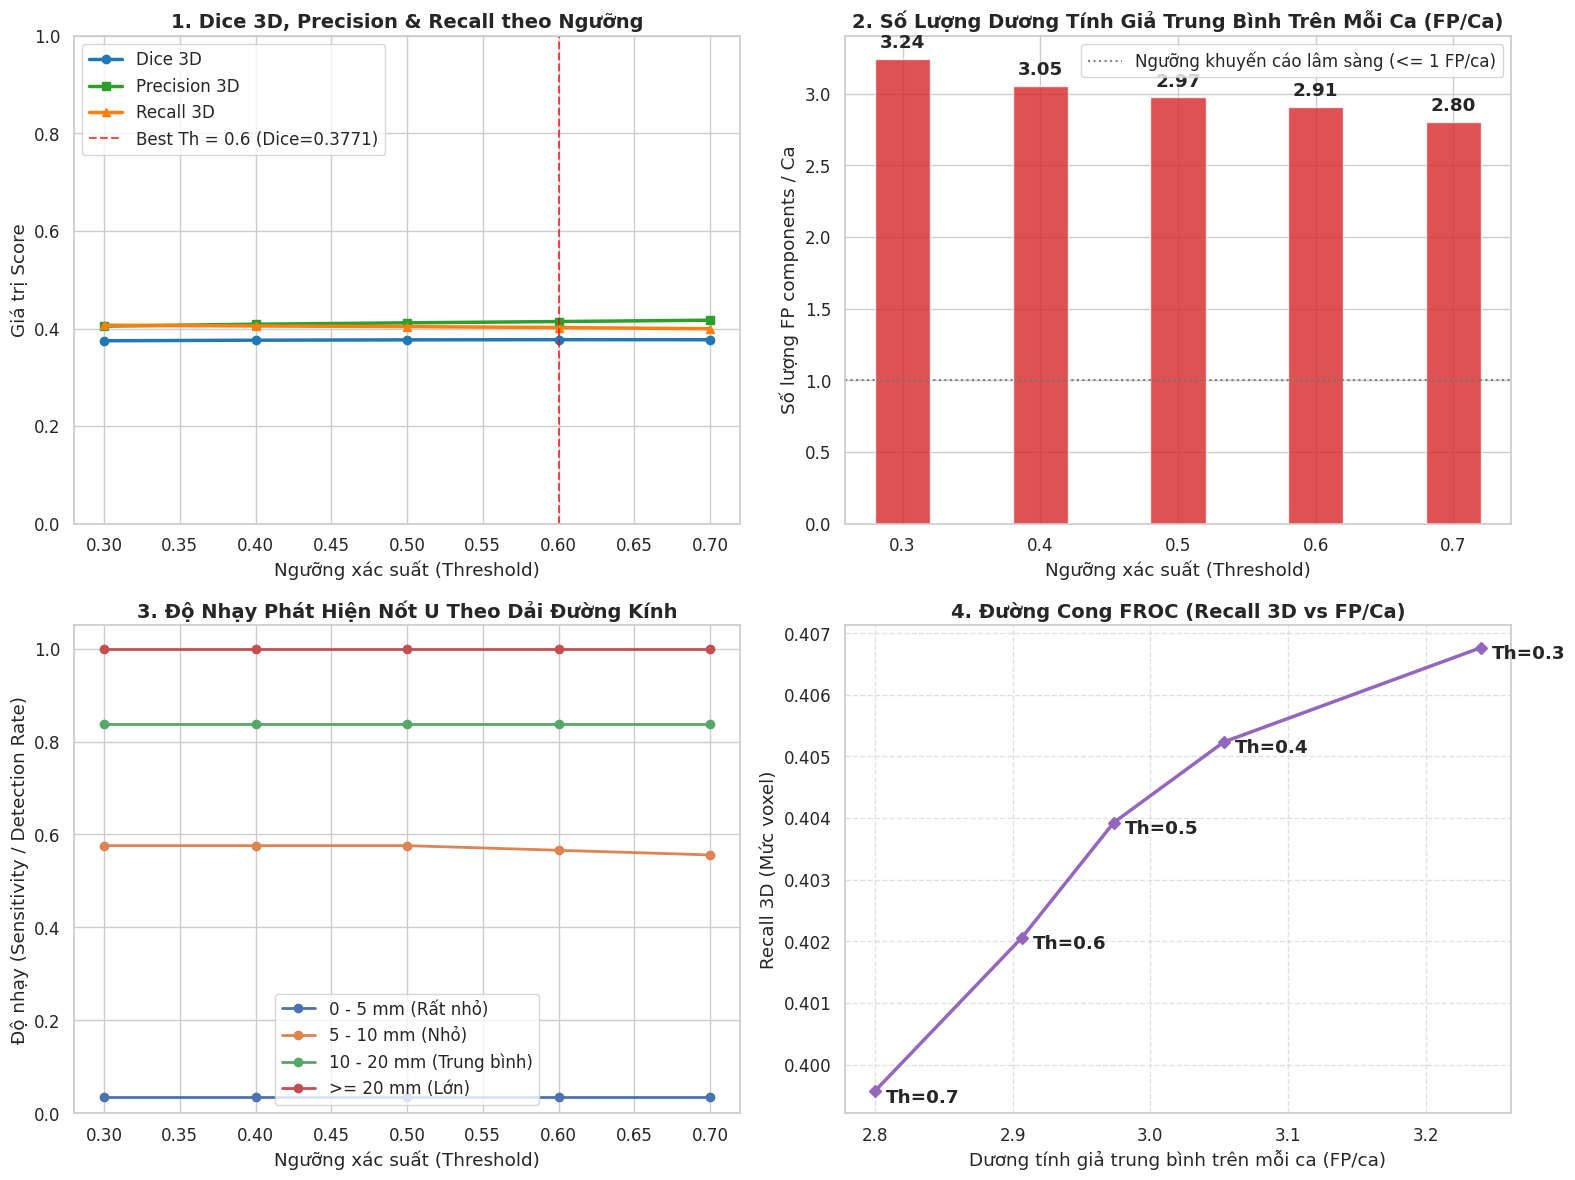

📊 Đã lưu biểu đồ chẩn đoán độ phân giải cao tại: /content/drive/MyDrive/COMPUTER SCIENCE/NAM4_HK1_(2026-2027)/CT208E/SOURCES/eval_results/step0_sweep/step0_diagnostic_charts.png


In [9]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Đọc kết quả từ thư mục đã lưu
out_dir = Path(EVAL_OUT_DIR)
pat_csv = out_dir / "sweep_r0_patients.csv"
nod_csv = out_dir / "sweep_r0_nodules.csv"

assert pat_csv.exists() and nod_csv.exists(), f"❌ Chưa tìm thấy file kết quả tại {out_dir}!"

P = pd.read_csv(pat_csv)
N = pd.read_csv(nod_csv)

print("=" * 70)
print("📊 BẢNG TỔNG HỢP HIỆU NĂNG 3D MỨC BỆNH NHÂN (TRUNG BÌNH THEO NGƯỠNG)")
print("=" * 70)
summary_df = P.groupby("th")[["dice", "precision", "recall", "fp_comps"]].mean().reset_index()
summary_df.columns = ["Ngưỡng (Th)", "Dice 3D", "Precision 3D", "Recall 3D", "FP / Ca (fp_comps)"]
display(summary_df.round(4))

print("\n" + "=" * 70)
print("🎯 BẢNG ĐỘ NHẠY PHÁT HIỆN NỐT U THEO DẢI ĐƯỜNG KÍNH (MM)")
print("=" * 70)
BINS = [(0, 5), (5, 10), (10, 20), (20, 1e9)]
bin_names = ["0 - 5 mm (Rất nhỏ)", "5 - 10 mm (Nhỏ)", "10 - 20 mm (Trung bình)", ">= 20 mm (Lớn)"]
sens_rows = []
for (lo, hi), bname in zip(BINS, bin_names):
    sub = N[(N["diam"] >= lo) & (N["diam"] < hi)]
    if len(sub) > 0:
        row = {"Dải kích thước": bname, "Số nốt GT": len(sub) // len(P["th"].unique())}
        th_sens = sub.groupby("th")["detected"].mean().to_dict()
        for th, val in th_sens.items():
            row[f"Th={th}"] = round(val, 3)
        sens_rows.append(row)

sens_df = pd.DataFrame(sens_rows)
display(sens_df)

# =============================================================================
# VẼ ĐỒ THỊ CHUYÊN SÂU
# =============================================================================
sns.set_theme(style="whitegrid", font_scale=1.1)
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Dice, Precision, Recall vs Threshold
ax1 = axes[0, 0]
ax1.plot(summary_df["Ngưỡng (Th)"], summary_df["Dice 3D"], marker='o', linewidth=2.5, label="Dice 3D", color="#1f77b4")
ax1.plot(summary_df["Ngưỡng (Th)"], summary_df["Precision 3D"], marker='s', linewidth=2.5, label="Precision 3D", color="#2ca02c")
ax1.plot(summary_df["Ngưỡng (Th)"], summary_df["Recall 3D"], marker='^', linewidth=2.5, label="Recall 3D", color="#ff7f0e")
best_th_idx = summary_df["Dice 3D"].idxmax()
best_th = summary_df.loc[best_th_idx, "Ngưỡng (Th)"]
best_dice = summary_df.loc[best_th_idx, "Dice 3D"]
ax1.axvline(best_th, color='red', linestyle='--', alpha=0.7, label=f"Best Th = {best_th} (Dice={best_dice:.4f})")
ax1.set_title("1. Dice 3D, Precision & Recall theo Ngưỡng", fontsize=14, fontweight="bold")
ax1.set_xlabel("Ngưỡng xác suất (Threshold)")
ax1.set_ylabel("Giá trị Score")
ax1.set_ylim([0.0, 1.0])
ax1.legend()

# 2. FP Comps / Patient vs Threshold
ax2 = axes[0, 1]
bars = ax2.bar(summary_df["Ngưỡng (Th)"].astype(str), summary_df["FP / Ca (fp_comps)"], color="#d62728", alpha=0.8, width=0.4)
ax2.axhline(1.0, color='gray', linestyle=':', label="Ngưỡng khuyến cáo lâm sàng (<= 1 FP/ca)")
ax2.set_title("2. Số Lượng Dương Tính Giả Trung Bình Trên Mỗi Ca (FP/Ca)", fontsize=14, fontweight="bold")
ax2.set_xlabel("Ngưỡng xác suất (Threshold)")
ax2.set_ylabel("Số lượng FP components / Ca")
for bar in bars:
    yval = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2, yval + 0.05, f"{yval:.2f}", ha='center', va='bottom', fontweight='bold')
ax2.legend()

# 3. Sensitivity by Nodule Size
ax3 = axes[1, 0]
for idx, row in sens_df.iterrows():
    bname = row["Dải kích thước"]
    y_vals = [row[f"Th={th}"] for th in summary_df["Ngưỡng (Th)"]]
    ax3.plot(summary_df["Ngưỡng (Th)"], y_vals, marker='o', linewidth=2, label=bname)
ax3.set_title("3. Độ Nhạy Phát Hiện Nốt U Theo Dải Đường Kính", fontsize=14, fontweight="bold")
ax3.set_xlabel("Ngưỡng xác suất (Threshold)")
ax3.set_ylabel("Độ nhạy (Sensitivity / Detection Rate)")
ax3.set_ylim([0.0, 1.05])
ax3.legend()

# 4. FROC Curve (Recall vs FP/case)
ax4 = axes[1, 1]
ax4.plot(summary_df["FP / Ca (fp_comps)"], summary_df["Recall 3D"], marker='D', color="#9467bd", linewidth=2.5)
for i, txt in enumerate(summary_df["Ngưỡng (Th)"]):
    ax4.annotate(f"Th={txt}", (summary_df.loc[i, "FP / Ca (fp_comps)"], summary_df.loc[i, "Recall 3D"]),
                 textcoords="offset points", xytext=(8, -8), ha='left', fontweight='bold')
ax4.set_title("4. Đường Cong FROC (Recall 3D vs FP/Ca)", fontsize=14, fontweight="bold")
ax4.set_xlabel("Dương tính giả trung bình trên mỗi ca (FP/ca)")
ax4.set_ylabel("Recall 3D (Mức voxel)")
ax4.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
chart_path = out_dir / "step0_diagnostic_charts.png"
plt.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"📊 Đã lưu biểu đồ chẩn đoán độ phân giải cao tại: {chart_path}")

### 2.4 Kết Luận Đo Lường & Xuất Báo Cáo Y Tế (`STEP0_EVALUATION_REPORT.md`)

**Bảng quy chuẩn kết luận lâm sàng**:
| Quan sát từ kết quả | Kết luận lâm sàng | Hành động tương ứng cho các bước tiếp theo |
|---|---|---|
| `fp_comps` lớn (≫ 1/ca) & Precision ≪ Recall | Dương tính giả là nút thắt chính | Giảm `pos_weight` xuống 2.0-3.0, tăng tỷ lệ mẫu âm tính `neg-ratio` lên 0.5-1.0, nâng ngưỡng inference |
| Độ nhạy nốt < 5 mm rất thấp (< 30%) | Mất nốt nhỏ do cắt ngưỡng 20mm² khi dựng cache | Hạ ngưỡng lọc train xuống 0 mm² (`--min-train-area 0`), chỉ lọc ở hậu xử lý |
| Đỉnh Dice 3D đạt tại ngưỡng $\ne 0.5$ | Ngưỡng bị lệch do tỷ trọng phạt mất mát | Chọn ngưỡng tối ưu trên tập Validation để áp dụng cho báo cáo Test |

In [10]:
import datetime

best_idx = summary_df["Dice 3D"].idxmax()
best_th = summary_df.loc[best_idx, "Ngưỡng (Th)"]
best_dice = summary_df.loc[best_idx, "Dice 3D"]
best_prec = summary_df.loc[best_idx, "Precision 3D"]
best_rec = summary_df.loc[best_idx, "Recall 3D"]
best_fp = summary_df.loc[best_idx, "FP / Ca (fp_comps)"]

report_content = f"""# 📋 BÁO CÁO KẾT QUẢ ĐO LƯỜNG BƯỚC 0 (STEP 0 MEASUREMENT REPORT)
**Mô hình đánh giá**: `{Path(CHECKPOINT_PATH).name}`
**Thư mục checkpoint**: `{CHECKPOINT_PATH}`
**Thời gian thực hiện**: {datetime.datetime.now().strftime('%Y-%m-%d %H:%M:%S')}
**Tập dữ liệu**: Validation set ({P['pid'].nunique()} bệnh nhân)

---

### 1. Kết Quả Quét Ngưỡng 3D Mức Bệnh Nhân
- **Ngưỡng tối ưu Dice 3D**: `Threshold = {best_th}`
- **Hiệu năng tại ngưỡng tối ưu**:
  - **Dice 3D**: `{best_dice:.4f}`
  - **Precision 3D**: `{best_prec:.4f}`
  - **Recall 3D**: `{best_rec:.4f}`
  - **Dương tính giả trung bình**: `{best_fp:.2f} FP/ca`
- **So sánh với ngưỡng mặc định 0.5**:
  - Dice 3D tại 0.5: `{summary_df.loc[summary_df['Ngưỡng (Th)'] == 0.5, 'Dice 3D'].values[0] if 0.5 in summary_df['Ngưỡng (Th)'].values else 'N/A'}`

---

### 2. Độ Nhạy Theo Kích Thước Nốt U
{sens_df.to_markdown(index=False)}

---

### 3. Khuyến Nghị Hành Động (Action Plan) Cho Các Bước Tiếp Theo
1. **Dương tính giả**: {'⚠️ fp_comps > 1/ca, cần giảm pos_weight và tăng lát âm tính (neg_ratio >= 0.5)' if best_fp > 1.0 else '✅ Mức độ FP/ca nằm trong giới hạn kiểm soát tốt.'}
2. **Nốt nhỏ (< 5mm)**: Khuyến nghị hạ ngưỡng diện tích train xuống 0 mm² lúc dựng chỉ mục để bảo tồn toàn vẹn nốt u nhỏ trong quá trình học.
3. **Kích thước ảnh**: Giữ `IMAGE_SIZE = 512` hoặc cân nhắc `448` nếu không có ca bệnh nào bị cắt mất nhãn trong kiểm tra FOV.

---
*Báo cáo được tự động sinh bởi Colab Step 0 Measurement Notebook.*
"""

report_file = out_dir / "STEP0_EVALUATION_REPORT.md"
with open(report_file, "w", encoding="utf-8") as f:
    f.write(report_content)

print(f"✅ ĐÃ XUẤT THÀNH CÔNG BÁO CÁO TẠI:\n   {report_file}")
print("\n" + "=" * 70)
print(report_content)
print("=" * 70)

✅ ĐÃ XUẤT THÀNH CÔNG BÁO CÁO TẠI:
   /content/drive/MyDrive/COMPUTER SCIENCE/NAM4_HK1_(2026-2027)/CT208E/SOURCES/eval_results/step0_sweep/STEP0_EVALUATION_REPORT.md

# 📋 BÁO CÁO KẾT QUẢ ĐO LƯỜNG BƯỚC 0 (STEP 0 MEASUREMENT REPORT)
**Mô hình đánh giá**: `best_model.pth`
**Thư mục checkpoint**: `/content/drive/MyDrive/COMPUTER SCIENCE/NAM4_HK1_(2026-2027)/CT208E/SOURCES/mamba_unet/runs/mamba_colab_500item_25epoch_extra_test/best_model.pth`
**Thời gian thực hiện**: 2026-11-11 10:34:32
**Tập dữ liệu**: Validation set (75 bệnh nhân)

---

### 1. Kết Quả Quét Ngưỡng 3D Mức Bệnh Nhân
- **Ngưỡng tối ưu Dice 3D**: `Threshold = 0.6`
- **Hiệu năng tại ngưỡng tối ưu**:
  - **Dice 3D**: `0.3771`
  - **Precision 3D**: `0.4143`
  - **Recall 3D**: `0.4021`
  - **Dương tính giả trung bình**: `2.91 FP/ca`
- **So sánh với ngưỡng mặc định 0.5**:
  - Dice 3D tại 0.5: `0.3767785158182296`

---

### 2. Độ Nhạy Theo Kích Thước Nốt U
| Dải kích thước          |   Số nốt GT |   Th=0.3 |   Th=0.4 |   Th=0.5 |   T

In [11]:
# 2. Lệnh tự động tắt máy SAU KHI huấn luyện xong
from google.colab import runtime
runtime.unassign()